# 2. Single Dispersive Interface: Wavelength-Dependent Optical Constants

## Physical Motivation & Learning Objectives
Real optoelectronic materials exhibit **chromatic dispersion** where the complex refractive index $\tilde{n}(\lambda) = n(\lambda) + i \kappa(\lambda)$ varies with wavelength. In this tutorial:
1. We simulate a planar interface between air and crystalline silicon using tabulated optical constants (`materials.Si_c`).
2. We evaluate how interband transitions in the ultraviolet affect reflectance and absorbance.
3. We parallelize wavelength sweeps using Python's `concurrent.futures`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Layer Definitions & Material Dispersion Setup

We sweep across the near-UV to near-infrared spectrum ($\lambda \in [300, 1100]$ nm). Silicon's refractive index is automatically interpolated from experimental optical constants.


In [2]:
wavelengths = np.linspace(300, 1100, 17)
period = 300.0  # nm

light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]
superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Si_c, loss=True)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))
print(f"Evaluated {len(stacks_list)} wavelengths across 300-1100 nm.")


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore can

## Dispersive Reflection and Absorption Spectra


<ipython-input-1-c4b8559253c8>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-1-c4b8559253c8>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


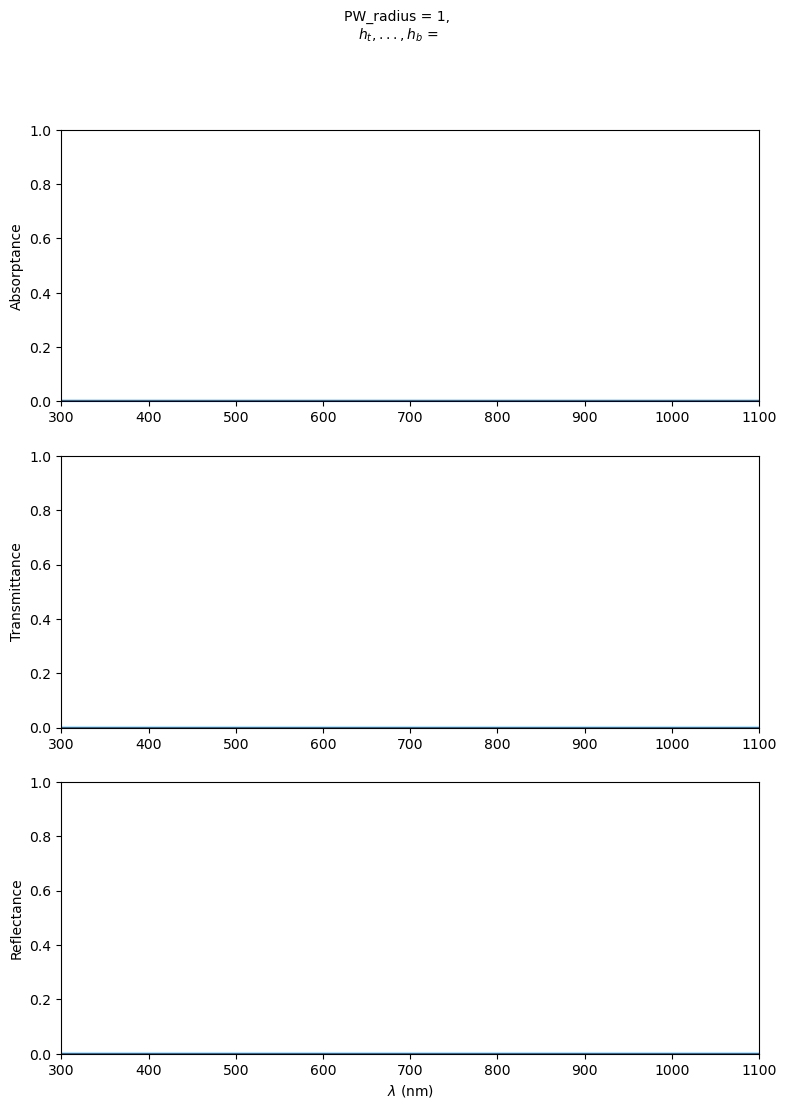

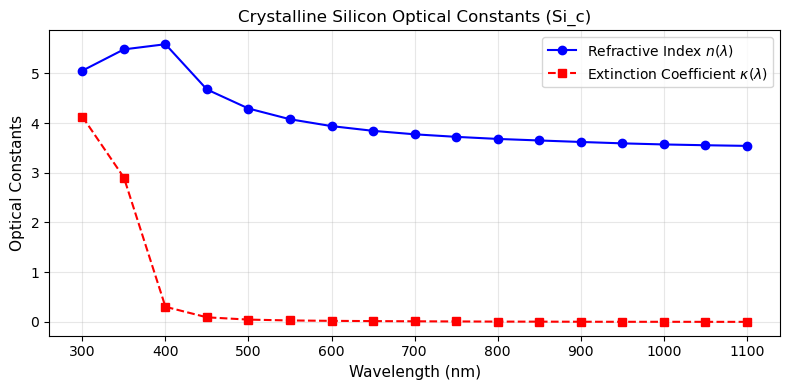

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, save_pdf=False, save_txt=False)
plt.show()

# Plot Si optical constants
si_n = [float(np.real(materials.Si_c.n(wl))) for wl in wavelengths]
si_k = [float(np.imag(materials.Si_c.n(wl))) for wl in wavelengths]

fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
ax.plot(wavelengths, si_n, 'b-o', label=r'Refractive Index $n(\lambda)$')
ax.plot(wavelengths, si_k, 'r--s', label=r'Extinction Coefficient $\kappa(\lambda)$')
ax.set_xlabel('Wavelength (nm)', fontsize=11)
ax.set_ylabel('Optical Constants', fontsize=11)
ax.set_title('Crystalline Silicon Optical Constants (Si_c)', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


## Physical Interpretation
- Near $\lambda \approx 370$ nm, silicon exhibits peak absorption and high refractive index ($n > 5$), causing reflectance to exceed $50\%$.
- As wavelength extends beyond the silicon band edge ($\lambda > 1100$ nm), the extinction coefficient $\kappa \to 0$, rendering silicon transparent.
